In [36]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier  #분류
from sklearn.neighbors import KNeighborsRegressor   #예측
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동생성 라이브러리
from sklearn.linear_model import Ridge              #릿지
from sklearn.linear_model import Lasso              #라쏘

from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler # 정규화 클래스
from sklearn.model_selection import train_test_split

In [37]:
# defree=5,1,15,20 등 넣어보고
# 릿지규제사용
# alpha 값 변경해서 최상의 모델을 구현하시오

In [38]:
df= pd.read_csv('data/perch_full.csv')
df.head(2)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00


In [39]:
# 무게 데이터 (label)
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [40]:
# 데이터 분리
train_data, test_data, train_label, test_label=train_test_split(df,perch_weight, random_state=42)
train_data[:1]

,length,height,width
8,19.6,5.14,3.04


In [41]:
# 특성값추가
poly=PolynomialFeatures(degree=2,include_bias=False)
poly.fit(train_data)

train_poly= poly.transform(train_data)
test_poly= poly.transform(test_data)

train_poly[:1]

array([[ 19.6   ,   5.14  ,   3.04  , 384.16  , 100.744 ,  59.584 ,
         26.4196,  15.6256,   9.2416]])

In [42]:
print(poly.get_feature_names_out())

['length' ' height' ' width' 'length^2' 'length  height' 'length  width'
 ' height^2' ' height  width' ' width^2']


In [43]:
# 3개 데이터를 가지고

# 학습
lr=LinearRegression()
lr.fit(train_data, train_label)

# 예측
predict=lr.predict(test_data)
print('예측:',predict)

# 정확도
score=lr.score(train_data, train_label)
score2=lr.score(test_data, test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

예측: [-322.78309496   52.96101903  329.77783424  171.46884473  149.65836217
  789.639144    383.68482432  250.05247716  813.2470793   126.13660027
  980.20626415  -33.35965799  357.76466578  421.8675313 ]
train 정확도 :  0.9559326821885706
test 정확도 :  0.8796419177546366


In [44]:
# degree = 2 / 특성을 9개로 변경해서 예측
# 데이터 학습
lr = LinearRegression()
lr.fit(train_poly,train_label)
# 데이터 예측
predict = lr.predict(test_poly)
print('예측 : ',predict)
# 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

예측 :  [  29.31340356   37.06927364  251.83284456  114.16483881  130.19864962
  780.17335409  304.80129313  178.36971814  911.24229748  101.88050671
 1174.97238267   38.31371268  287.9800756   276.64644375]
train 정확도 :  0.9903183436982124
test 정확도 :  0.9714559911594145


In [45]:
# 특성값추가
# degree의 값을 변경하여 test의 정확도가 -인것을 찾아보기

poly=PolynomialFeatures(degree=17,include_bias=False)
poly.fit(train_data)

train_poly= poly.transform(train_data)
test_poly= poly.transform(test_data)

In [46]:
# degree = 17 
# 데이터 학습
lr = LinearRegression()
lr.fit(train_poly,train_label)
# 데이터 예측
predict = lr.predict(test_poly)
print('예측 : ',predict)
# 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

예측 :  [ 162.77113101  162.79491673  160.14689041  163.01538667  162.50522395
  629.86743389  128.12669465  163.20251711  838.8168149   162.82974185
 -754.35372289  162.77298931  161.68679393  178.02117583]
train 정확도 :  0.9378712937807022
test 정확도 :  -1.2988231241629196


In [47]:
# 정규화 작업
ss=StandardScaler()
ss.fit(train_poly)

train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [48]:
alpha_list = [0.001,0.01,0.1,1,10,100]
# 릿지, 라쏘 규제 2가지 형태
train_score = []
test_score = []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    # 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
print('완료') 

완료


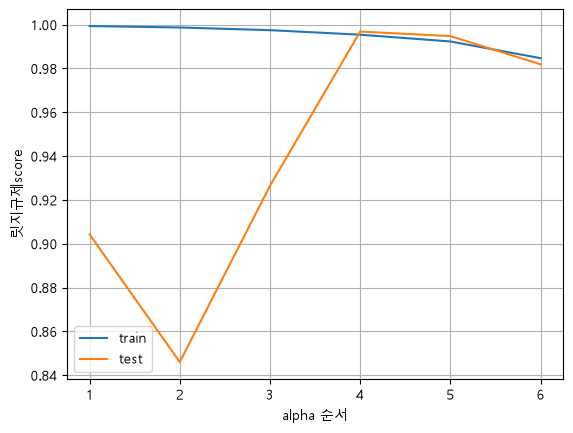

In [50]:
# 선그래프
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)

plt.grid()

plt.legend(['train','test'])


plt.xlabel('alpha 순서')
plt.ylabel('릿지규제score')
plt.show()

In [52]:
# 릿지 규제화
ridge = Ridge(alpha=100)
ridge.fit(train_scaled,train_label)
# 정확도
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)

print('train 정확도 : ',score)
print('test 정확도 : ',score2)

train 정확도 :  0.9846824250611482
test 정확도 :  0.9818916802306978
